In [1]:
## Overvoltage at 48 V is 4.5V (from noise_extraction.ipynb)
NCA = 0.35 # first VUV4 paper, 163K

# from second Giacomo nEXO paper. Our SiPM is VUV4-Q-50
# looks like same batch according to slope of noise
NCA = 0.17

hScale = 32.

# still have the issue of passing in variables to both sets of analysis
# use argparse or a new python 'module', but for the module we'd have to use importlib.reload()
# to avoid restarting the kernel everything I want to change the binning (or something similar)

# from Zhiheng's message
# I would say that the position of the collimator changed a little bit
# but we also redid the measurement, so the 28.5 would be more accurate.
# We also rotated the collimator on 0303, so I'd say everything before that
# is closer to 28cm, and everything after is closer to 28.5


#### What does this code do (eventually) ####

# make a global "buildCorrectedRC"

# dataSet class
## pass it some rcList

# write 'makeDataObj.py' so you can build the data RunClass objects in 1 line
  # it should include some arguments to pass/select the runs and variables we want

# get MCdataSet working
## open files from a directory
## ensure that the physPars are all equal
## do NCA correction

In [2]:
# need to implement LP filter. also in G4_runClasses and mac. right now set to false
# see xxLP in code

In [3]:
## Python Stuff
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

os.environ.get("ROOTSYS")

"""
run with:
see code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab see bashprofile
"""

'\nrun with:\nsee code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab see bashprofile\n'

In [4]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(300)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()
# ROOT.disableJSVis()

Welcome to JupyROOT 6.27/01


In [5]:
## prepping to get tools for real data
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME"))

# so we can use makeDataObj.py
sys.path.append(os.environ.get("CF4HOME")+"/comp1/")

## Loading Atown's tools
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

print(sys.path)


['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1/']


In [6]:
## -------- Loading in real data -------- ##
checkName = 'rcList'
if checkName in globals() or checkName in locals():
   print(f"{checkName} is declared, not reloading data")
else:
    print(f"{checkName} is not declared.")
    makeDataArg = str(os.environ.get("CF4HOME")+"/comp1/" + "makeDataObj.py")
    %run $makeDataArg
# %run $makeDataArg

# xx is running this multiple times okay? 
# ------------- Get and build the bkg corrected spectra ------------- ##
print("\n Bare:")
for rc in rcl_cs_bare_heights:
  rc.FindClosestRC(rcl_Bkg_0310)
  rc.BuildCorrSpectrum()
  rc.setup_forComparison()
  print(rc.mHeight)

print("\n Filtered")
for rc in rcl_cs_lp_heights:
  rc.FindClosestRC(rcl_Bkg_0411)
  rc.BuildCorrSpectrum()
  rc.setup_forComparison()
  print(rc.mHeight)

rcList is not declared.
hi austin! Running makeDataObj
Done Calculating SPE

 Bare:
26.5
28
30.5
32
34.5

 Filtered
26
28.5
30.5
32


In [7]:
FindRCbyHeight = lambda h, rclist: next((rc for rc in rclist if rc.GetHeight() == h), None)

# this is all the files in a single folder
class RealDataSet(object):

  def __init__(self):
    
    ## only Cs data right now
    self.mCsBare = []
    self.mCsLP = []

    self.mCoBare = []
    self.mCoLP = []

    return

  def print(self):
    
    return
  
  # def passMCset(self, mcData, options: str = ""):

  #   self.checkMapping()
  #   return
  
  # def calcChi2():

  
  # def plot_singleRows(self, fig: plt.figure, selection = "mCsBare",):
  #   Nrows = len(getattr(self, selection))

  #   for i, rc in enumerate(getattr(self, selection)):
  #     ax = fig.add_subplot.hist(Nrows, 1, i+1)
  #     ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype = "step", label = "data " + str(hScale - rcBare_55cm.mHeight) + " cm")
  #   return


In [8]:
realData = RealDataSet()

## looking for specific RC objects by height (data runs)
# FindRCbyHeight = lambda h, rclist: next((rc for rc in rclist if rc.GetHeight() == h), None)
cs_bare_heights = [x for x in cs_bare_heights if x != 34.5] # get rid of the data below SiPM
print(cs_bare_heights)


# selecting the RC objects to pass to realData
bareCsData_rc = [FindRCbyHeight(h, rcl_cs_bare_heights) for h in cs_bare_heights] # prune off 34.5 one
bareCsData_rc = sorted(bareCsData_rc, key=lambda rc: hScale - rc.mHeight) # sorting
print(type(bareCsData_rc[0]))

print("bare Cs data Heights", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in bareCsData_rc]; print("")


rcl_cs_lp_heights = sorted(rcl_cs_lp_heights, key=lambda rc: hScale - rc.mHeight) # sorting
lpCsData_rc = rcl_cs_lp_heights # rcl comes from getDataObjs script
print("\nlp Cs data Heights", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in lpCsData_rc]; print("")

bareCsData_rc[0].print()

## assigning rc lists to realData object
realData.mCsBare = bareCsData_rc
realData.mCsLP = lpCsData_rc
# xxLP do others here
# mapping of dif heights will be an issue. dif heights in MC or change h values in rc objects

[26.5, 28, 30.5, 32]
<class 'helpers.anaStructs.RunClass'>
bare Cs data Heights: 0.0 1.5 4.0 5.5 

lp Cs data Heights: 0.0 1.5 3.5 6.0 

runID: 202203101534
Nevents: 24688.00,   time: 13.01 min
average Rate: 31.62 Hz
height = 32.00
chID:0: spe = 151.66 +/- 0.38     maxChi2 = 0.00
chID:1: spe = 154.86 +/- 0.43     maxChi2 = 0.00
chID:2: spe = 154.51 +/- 2.68     maxChi2 = 0.00


Text(0, 0.5, 'chi2')

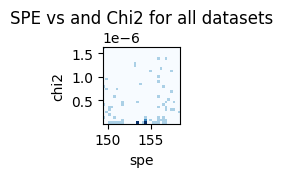

In [9]:
## checking spe and chi2 values
plt.figure(figsize=(1, 1))
plt.hist2d(speList, chi2list, bins=30, cmap='Blues')
plt.title("SPE vs and Chi2 for all datasets")
plt.xlabel("spe")
plt.ylabel("chi2")
# plt.show()

In [10]:
# this will take in a folder and create the MC dataset
# # and an set 

# Geant4 code and helpers
sys.path.append(os.environ.get("CF4G4"))
import Batch.helpers.FileGetters as FG

from Batch.helpers.G4_runClasses import *
from Batch.helpers.G4_macHelpers import *

# this is all the files in a single folder
class MCdataSet(object):

  def __init__(self, folderPath: str):
    
    files = FG.get_all_root_files(folderPath)
    print(files)
    # open everything as FullMCRun
    # sort by mRunPars

    # entire trackers
    self.mAllRuns = [FullMCRun(macName = f[:-len(".root")]) for f in files]
    

    ## loading (Bare) Cs data
    self.mCsBareList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == False and mc.mRunPars.gammaSrc == "Cs137")]
    self.mCsBareList = sorted(self.mCsBareList, key=lambda rc: rc.mRunPars.gammaHeight) # sorting
    # [print(type(mc.mRunPars.gammaHeight)) for mc in self.mCsBareList]
    self.mCsBareRateScaling = 0.1 #float
    
    self.mCsLpList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == True and mc.mRunPars.gammaSrc == "Cs137")]

    ## Co data
    # self.mCoBareList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == False and mc.mRunPars.gammaSrc == "Co57")]
    # self.mCoLPList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == True and mc.mRunPars.gammaSrc == "Co57")]
    self.mCoRateScaling = 0.1 #float

    ## other data\
    return

  def doCAcorrection_BinomialMC(self, nCA):
    done = [mc.doCAcorrection_BinomialMC(nCA) for mc in self.mAllRuns]
    return
  
  # for "mNPE", "mNPE_corr", call one of the doCAcorrection first
  def setup_forComparison(self, Nbins = 100, lowRange = 0.5, maxRange = 100.5, variable = "mNPE"):
    done = [mc.setup_forComparison(Nbins, lowRange, maxRange, variable) for mc in self.mAllRuns]
    return
  
  # def compare_dicts(dict1, dict2):
  #   return all(dict1.get(key) == dict2.get(key) for key in dict1.keys())

  def print(self):
    
    return
  
  # check that all physPars are the same (they should be)
  # detPars aren't implemented yet (only PDE)
  def check_physPars_andDetPars(self, verbose = False):

    physParList = [mc.mPhysPars for mc in self.mCsBareList + self.mCsLpList]
    if verbose:
      [print(mc.mPhysPars.__dict__, "\n") for mc in self.mCsBareList]
    return all(physParList[0] == p1 for p1 in physParList[1:])

In [11]:
pBatch1 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/"

mc1 = MCdataSet(pBatch1+"/0/")

# setup for physics comparisons
mc1.doCAcorrection_BinomialMC(NCA)
mc1.setup_forComparison(Nbins, binLow, binHigh)

# len(mc1.mCsBareList)
# mc1.mCsBareList[0].mPhysPars.ly = 1000

# blah = FullMCRun(pBatch1+"/0/"+"Cs137_ly_3000_h_0_ly")
for mc in mc1.mCsBareList:
  h = mc.mRunPars.gammaHeight
  print(h)

mc1.check_physPars_andDetPars(verbose = False)
print(mc1.mCsBareList[0].mPhysPars.__dict__)
# np.mean(mc1.mCsBareList[3].mNPE)

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_0_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_5d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_4d0_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_1d5_ly.root']
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_0_ly.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_5d5_ly.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_4d0_ly.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput//0/Cs137_ly_3000_h_1d5_ly.root
0.0
1.5
4.0
5.5
{'str_medium': '/setMateria

In [23]:
# should have this working as a two way object (rc and mc also know about it)
class rcMCpair(object):

  def __init__(self, rc, mc):
    self.mc = mc
    self.rc = rc
    self.height = mc.mRunPars.gammaHeight
    self.countLimit = 10
    return
  
  def GuessBinRange(self, firstBin):

    self.firstBin = firstBin
    self.lastBin = np.where(self.rc.mBin_rawCounts < self.countLimit)[0][0]

    # badly handle bins less than 10
    if self.rc.mBin_rawCounts[self.lastBin] <= 0:
      self.lastBin -= 1
    while self.mc.mRaw_Counts[self.lastBin] <= self.countLimit:
      self.lastBin -= 1
    return

  ##----------##
  def GuessScaling(self, firstBin = 1):

    self.GuessBinRange(firstBin)
    # analytic scaling
    dataArea = sum(self.rc.mBin_rawCounts[self.firstBin:self.lastBin])
    self.mcScale = dataArea/np.sum(self.mc.mRaw_Counts[self.firstBin:self.lastBin])

    # print(np.sum(self.rc.mBin_rawCounts[self.firstBin:self.lastBin]))
    # print(self.mcScale * np.sum(self.mc.mRaw_Counts[self.firstBin:self.lastBin]))
    # print(self.mcScale)
    
    return self.mcScale

  ##----------##
  def computeChi2_reduced(self, scaling):
  
    mcBins = scaling * self.mc.mRaw_Counts[self.firstBin:self.lastBin]
    dataBins = self.rc.mBin_rawCounts[self.firstBin:self.lastBin]
    self.chi2 = np.sum((dataBins - mcBins)**2/mcBins)
    self.ndof = self.lastBin - self.firstBin + 1 # i think +1 here is right?
    self.redChi2 = self.chi2/(self.ndof - 1)
    return self.redChi2

class Comparator(object):

  def __init__(self, realData):

    self.mMCDataSet = None
    self.mRealData = realData # this never changes

    ## Cesium
    self.csBareMap = [None] * len(self.mRealData.mCsBare)
    self.hScale = hScale

    return
  
  def loadNewG4(self):
    # load it
    return True

  ## ensure 
  def do_mapping(self, heightsWanted = []):
    # how to track heights and map them to one another. 

    # check lengths
    # print(len(self.mMCDataSet.mCsBareList))
    # print(len(self.mRealData.mCsBare))

    # doing BareCs mapping
    for i, mc in enumerate(self.mMCDataSet.mCsBareList): # here mc is a FullMCRun object
      h = mc.mRunPars.gammaHeight # get height
      rc_withHeight = FindRCbyHeight(self.hScale - h, self.mRealData.mCsBare) # get real data
      # print(h, type(rc_withHeight))
      pair = rcMCpair(rc_withHeight, mc) # make pair object to map them together
      # print(hScale - rc_withHeight.mHeight, pair.mc.mRunPars.gammaHeight == self.hScale - rc_withHeight.mHeight) 
      self.csBareMap[i] = pair # assign pair to the map list
    
    # print(len(self.csBareMap))
    return
    
  def getFullReducedChi2(self, scaling):
    # cesium bare
    csBare_chi2 = np.sum([pair.computeChi2_reduced(scaling) for pair in self.csBareMap])

    return np.sum(csBare_chi2)


  def minimizeRateScaling(self): # nuisance parameter for these dataSets
    
    ## Cs 
    firstGuess = np.sum([pair.GuessScaling() for pair in self.csBareMap])/len(self.csBareMap)



    return firstGuess
  
  


# find the scaling nuisance parameter (minimize chi2) for the Cs dataset.
# only Bare for now (only have BareMC data)
# def scaleCs(startValue):


# comparator.mc1.mCsBareList[0].mPhysPars.ly

In [29]:
comp1 = Comparator(realData)
type(comp1.mRealData.mCsBare[0])
comp1.mMCDataSet = mc1
comp1.do_mapping()
print(type(comp1.csBareMap[0]))

scaleGuess = comp1.minimizeRateScaling()
print(scaleGuess)
comp1.getFullReducedChi2(scaleGuess/2)
# print(type(comp1.csBareMap[0]))
# comp1.getFullReducedChi2(0.1)

<class '__main__.rcMCpair'>


5425.597397859551

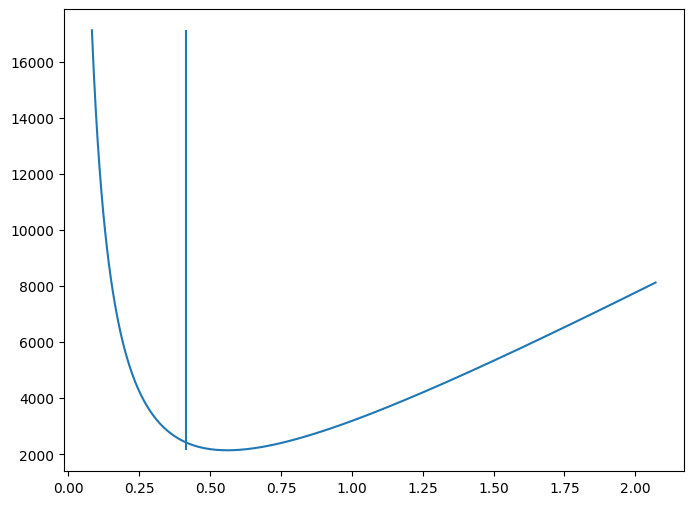

In [37]:
scalingX = np.linspace(scaleGuess/5., scaleGuess * 5., 300)
chi2Full = np.array([comp1.getFullReducedChi2(scale) for scale in scalingX])

fig, ax = plt.subplots(1, 1, figsize = (8, 6))

ax.plot(scalingX, chi2Full)
ax.vlines(scaleGuess, min(chi2Full), max(chi2Full))

plt.show()

In [ ]:
## loading in MC data
pathToFiles = os.environ.get("CF4G4")+"/Batch/may5_2023-manualTesting_gammaHeights/"

# dat = get_all_root_files(pathToFiles)
files = get_all_root_files(pathToFiles)
for f in files:
  print(f)
# print(files)

fname = "Cs137_1d5cm"
mc_1d5cm = FullMCRun(macName = pathToFiles+fname)
mc_1d5cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

fname2 = "Cs137_4cm"
mc_4cm = FullMCRun(macName = pathToFiles+fname2)
mc_4cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

fname3 = "Cs137_0cm"
mc_0cm = FullMCRun(macName = pathToFiles+fname3)
mc_0cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

# runList = [[rcBare_0cm, mc_0cm], [rcBare_1d5cm, mc_1d5cm], [rcBare_4cm, mc_4cm]]

fname4 = "Cs137_5d5"
mc_55cm = FullMCRun(macName = pathToFiles+fname4)
mc_55cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

hScale = 32. # H measured - this = height above SiPM (MC)
heightMapping = lambda h: hScale - h
print(heightMapping(28))
print(heightMapping(5.5))

mcList = [mc_0cm, mc_1d5cm, mc_4cm, mc_55cm]
dataList = [rcBare_0cm, rcBare_1d5cm, rcBare_4cm, rcBare_55cm]

# macList = 

Cs137_4cm_big.root
Cs137_-0d5cm.root
Cs137_4cm.root
Cs137_5d5.root
Cs137_0cm.root
Cs137_1d5cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_1d5cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_4cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_0cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_5d5.root
4.0
26.5


In [ ]:
# ## my test class to minimize per run ##

# class MCrun_fixedPars(object):
  
#   def __init__(self, physRuns, mcRuns): # pass a list of data and MC runs (RC objects and FullMCRun)

## scaling ##
binStart = 0
binEnd = 1

# scaling analytically with 1.5cm (first guess for nuisance parameter)
dataArea = sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd])

# mcCounts, mcEdges = np.histogram(mc_1d5cm.mNPE, bins = int(Nbins), range=(0, binHigh))
mcScale = dataArea/np.sum(mc_0cm.mRaw_Counts[binStart:binEnd]) # now it is 1
# mcScale *= 100.
  
print(np.sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd]))
print(mcScale * np.sum(mc_0cm.mRaw_Counts[binStart:binEnd]))


1678.0789355315483
1678.0789355315483


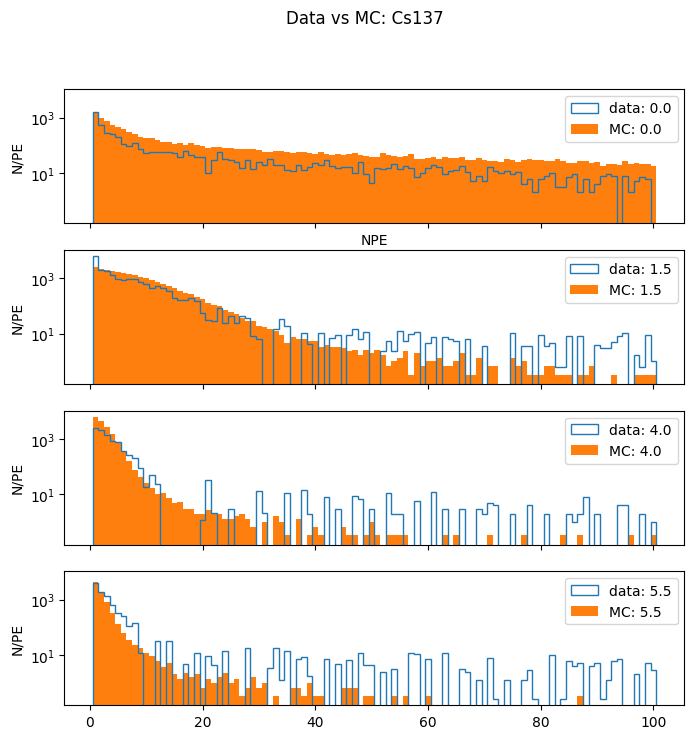

In [ ]:
fig, axs = plt.subplots(4, 1, figsize = (8, 8), sharey=True, sharex=True)
ax1 = axs[0]
ax2 = axs[1]
ax3 = axs[2]
ax4 = axs[3]

# mcScale = 0.3119 # from a fit, adding total chi2

# 32 = 0 cm run
# areaData = sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd])
ax1.hist(x = rcBare_0cm.mBinX, bins = rcBare_0cm.mBin_edges, weights = rcBare_0cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_0cm.mHeight))
ax1.hist(x = mc_0cm.mBinX, bins = mc_0cm.mBin_Edges, weights=mc_0cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_0cm.mRunPars.gammaHeight))

# 30.5 = 1.5 cm run
ax2.hist(x = rcBare_1d5cm.mBinX, bins = rcBare_1d5cm.mBin_edges, weights = rcBare_1d5cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_1d5cm.mHeight))
ax2.hist(x = mc_1d5cm.mBinX, bins = mc_1d5cm.mBin_Edges, weights=mc_1d5cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_1d5cm.mRunPars.gammaHeight))

# 34  =  4cm 
ax3.hist(x = rcBare_4cm.mBinX, bins = rcBare_4cm.mBin_edges, weights = rcBare_4cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale -rcBare_4cm.mHeight))
ax3.hist(x = mc_4cm.mBinX, bins = mc_4cm.mBin_Edges, weights=mc_4cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_4cm.mRunPars.gammaHeight))

# 26.5 = 5.5cm
ax4.hist(x = rcBare_55cm.mBinX, bins = rcBare_55cm.mBin_edges, weights = rcBare_55cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_55cm.mHeight))
ax4.hist(x = mc_55cm.mBinX, bins = mc_55cm.mBin_Edges, weights=mc_55cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_55cm.mRunPars.gammaHeight))
# plt.hist(x = mcEdges[:-1], bins = mcEdges, weights=mcCounts, label = "MC")

for ax in axs.flat:
  ax.set_ylabel("N/PE")
  ax.legend()

ax1.set_xlabel("NPE")
fig.suptitle("Data vs MC: Cs137")
ax1.set_yscale("log")
# ax1.set_ylim(0, 20)
# ax1.set_xlim(0, 30)

# plt.legend()
plt.show()
# print(rcBare_0cm.mBin_edges[0])

# mcEdges[0:4]

In [ ]:
from scipy.stats import ks_2samp
from scipy.stats import anderson_ksamp
from scipy.stats import chisquare
from scipy.stats import cramervonmises_2samp

from scipy.stats import chi2

import scipy.optimize as spOpt

import copy

In [ ]:
def totalChi2(scaleFactor, mcList, dataList, myInfo=[None, None], firstBin = 0, countLimit = 10.):
  chi2 = 0.
  totalNDOF = 0

  for mc, data in zip(mcList, dataList):
    # print(scaleFactor * mc.mRaw_Counts[0:20])
    lastBin = np.where(data.mBin_rawCounts < countLimit)[0][0]
    if data.mBin_rawCounts[lastBin] <= 0:
      lastBin -= 1
    while mc.mRaw_Counts[lastBin] <= countLimit:
      lastBin -= 1
    # print(lastBin, data.mBin_rawCounts[lastBin], scaleFactor * mc.mRaw_Counts[lastBin])

    mcBins = scaleFactor * mc.mRaw_Counts[firstBin:lastBin]
    dataBins = data.mBin_rawCounts[firstBin:lastBin]
    chi2Run = np.sum((dataBins - mcBins)**2/mcBins)

    totalNDOF += lastBin - firstBin
    chi2 += chi2Run

  myInfo[0] = scaleFactor
  myInfo[1] = chi2
  myInfo[2] = totalNDOF - 1
  # print(scaleFactor, "\n")
  return chi2/(totalNDOF - 1)

def totalReducedChi2(scaleFactor, mcList, dataList, myInfo=[None, None], firstBin = 0, countLimit = 10.):
  reducedChi2 = 0.

  for mc, data in zip(mcList, dataList):
    # print(scaleFactor * mc.mRaw_Counts[0:20])
    lastBin = np.where(data.mBin_rawCounts < countLimit)[0][0]
    if data.mBin_rawCounts[lastBin] <= 0:
      lastBin -= 1
    while mc.mRaw_Counts[lastBin] <= countLimit:
      lastBin -= 1
    # print(lastBin, data.mBin_rawCounts[lastBin], scaleFactor * mc.mRaw_Counts[lastBin])

    mcBins = scaleFactor * mc.mRaw_Counts[firstBin:lastBin]
    dataBins = data.mBin_rawCounts[firstBin:lastBin]
    chi2Run = np.sum((dataBins - mcBins)**2/mcBins)

    NDOF = lastBin - firstBin
    reducedChi2 += chi2Run/NDOF

  myInfo[0] = scaleFactor
  myInfo[1] = reducedChi2
  myInfo[2] = -1
  # print(scaleFactor, "\n")
  return reducedChi2

In [ ]:
info = [None, None, None]
infoReduced = copy.copy(info)

totalChi2(mcScale, mcList, dataList, info)

totalReducedChi2(mcScale, mcList, dataList, infoReduced)

print(info)
print(infoReduced)

[0.3307863070237627, 17193.35916330478, 66]
[0.3307863070237627, 1134.7910394947855, -1]


In [ ]:
fit = spOpt.minimize(totalChi2, x0 = [2*mcScale], args = (mcList, dataList, info), bounds = [[1e-4, 100.*mcScale]])
fitReduced = spOpt.minimize(totalReducedChi2, x0 = [2*mcScale], args = (mcList, dataList, infoReduced), bounds = [[1e-4, 100.*mcScale]])
print(mcScale)
print(fit)
print(info, "\n ------------------------------------- \n")
print(fitReduced)
print(infoReduced)

0.3307863070237627
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 257.12023436226167
        x: [ 3.093e-01]
      nit: 6
      jac: [ 0.000e+00]
     nfev: 18
     njev: 9
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>
[array([0.30931389]), 16969.93546790927, 66] 
 ------------------------------------- 

  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 1119.1720743288888
        x: [ 3.090e-01]
      nit: 6
      jac: [ 0.000e+00]
     nfev: 18
     njev: 9
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>
[array([0.30896858]), 1119.1720743288888, -1]


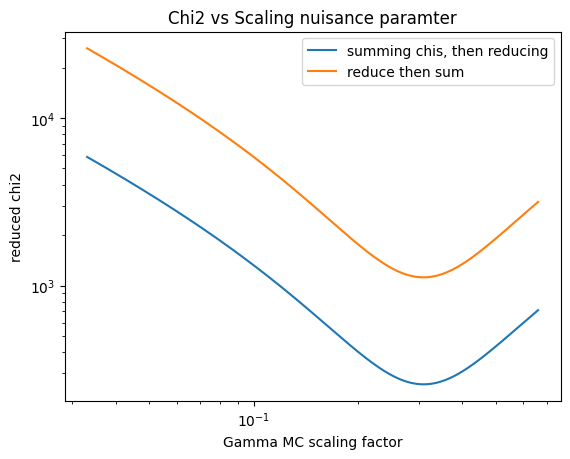

In [ ]:
## testing manually
totalChi2(mcScale, mcList, dataList, info)
x_scaleValues = np.linspace(mcScale/10., 2*mcScale, 1000)
y_chiValues = []
y_chiReduced = []

for scale in x_scaleValues:
  chi = totalChi2(scale, mcList, dataList, info)
  y_chiValues.append(chi)

  reducedChi = totalReducedChi2(scale, mcList, dataList, infoReduced)
  y_chiReduced.append(reducedChi)

plt.plot(x_scaleValues, y_chiValues, label = "summing chis, then reducing")
plt.plot(x_scaleValues, y_chiReduced, label = "reduce then sum")
plt.yscale("log")
plt.xscale("log")

plt.xlabel("Gamma MC scaling factor")
plt.ylabel("reduced chi2")
plt.title("Chi2 vs Scaling nuisance paramter")

plt.legend()

plt.show()

In [ ]:
endRange_ksTest = [60, 25, 12, 8]
# testing other methods of comparison
LLksp = 0.
LLcv = 0.
firstBin = binStart
  
for i, (mc, data) in enumerate(zip(mcList, dataList)):
  endRange = endRange_ksTest[i]
  dArr = data.mBin_rawCounts[firstBin:endRange]
  mcArr = mcScale * mc.mRaw_Counts [firstBin:endRange]

  ks_statistic, ksp_value = ks_2samp(dArr, mcArr)
  # an_statistic, crit, ap_value = anderson_ksamp([dArr, mcArr], midrank = True)
  cram = cramervonmises_2samp(dArr, mcArr)

  myChi2 = (dArr - mcArr)**2/mcArr

  # print(i, mc, data)
  print(f"height:{mc.mRunPars.gammaHeight}   KS statistic: {ks_statistic:0.4f}, P-value: {ksp_value}")
  # print(f"   An statistic: {an_statistic:0.2E}, P-value: {ap_value}")
  print(f"   cram statistic: {cram.statistic:0.2E}, P-value: {cram.pvalue} \n")
  LLksp += ksp_value
  LLcv += cram.pvalue


print(f"KS Liklihood = {LLksp}")
print(f"CV Liklihood = {LLcv}")

height:0.0   KS statistic: 0.6333, P-value: 1.3069068729277308e-11
   cram statistic: 4.12E+00, P-value: 2.4123891773086825e-10 

height:1.5   KS statistic: 0.2400, P-value: 0.4754535018190584
   cram statistic: 2.02E-01, P-value: 0.26940666665146784 

height:4.0   KS statistic: 0.2500, P-value: 0.8689816711757754
   cram statistic: 8.33E-02, P-value: 0.732743229310735 

height:5.5   KS statistic: 0.3750, P-value: 0.6601398601398599
   cram statistic: 1.56E-01, P-value: 0.4313908313908314 

KS Liklihood = 2.0045750331477628
CV Liklihood = 1.4335407275942733


In [ ]:
## doing first KS test ##


ks_statistic, p_value = ks_2samp(rcBare_1d5cm.mBin_contents[binStart:binEnd], mcCounts[binStart:binEnd])

print(f"KS statistic: {ks_statistic}")
print(f"P-value: {p_value}")


AttributeError: 'RunClass' object has no attribute 'mBin_contents'

In [ ]:
len(rcBare_1d5cm.mBin_contents)
len(mcCounts)

80